# Simple Linear Regression – House Prices

**Goal:** Warm-up example: predict a house price from its area using one feature.

**Dataset:** `homeprices.csv` – 5 rows (area, price)

**Approach:** Fit `LinearRegression` on a single feature, inspect slope & intercept, predict new areas and plot the fitted line.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## Load the data

In [2]:
df = pd.read_csv('../data/homeprices.csv')
df

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


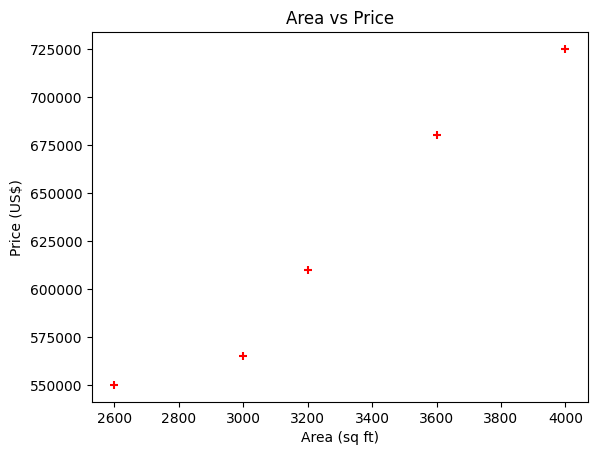

In [3]:
plt.scatter(df['area'], df['price'], color='red', marker='+')
plt.xlabel('Area (sq ft)')
plt.ylabel('Price (US$)')
plt.title('Area vs Price')
plt.show()

## Model training

In [4]:
# scikit-learn expects a 2D feature matrix, so select the column as a DataFrame
X = df[['area']]
y = df['price']

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [5]:
print('Slope (coef):', model.coef_[0])
print('Intercept   :', model.intercept_)

Slope (coef): 135.78767123287673
Intercept   : 180616.43835616432


In [6]:
new_areas = pd.DataFrame({'area': [3300, 5000]})
new_areas['predicted_price'] = model.predict(new_areas)
new_areas

,area,predicted_price
0,3300,628715.753425
1,5000,859554.794521


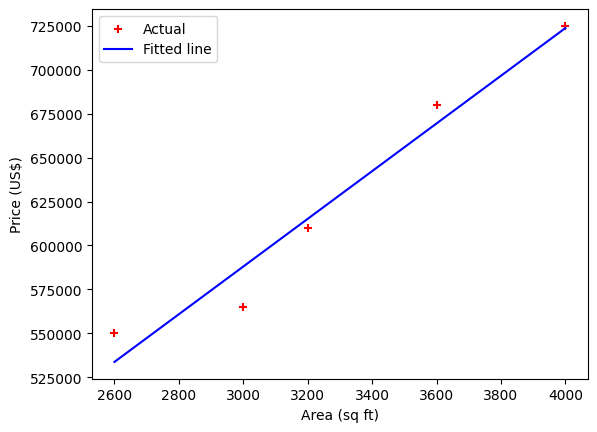

In [7]:
plt.scatter(df['area'], df['price'], color='red', marker='+', label='Actual')
plt.plot(df['area'], model.predict(X), color='blue', label='Fitted line')
plt.xlabel('Area (sq ft)')
plt.ylabel('Price (US$)')
plt.legend()
plt.show()

## Results & conclusion

* The model learns **price ≈ 135.8 × area + 180,616**.
* With only 5 samples there is no train/test split – this notebook is a warm-up to understand how `fit` / `predict` work.